# Shorts を出すと長尺の視聴は増えるか（日次・分布ラグ回帰）

- **問い**：Shorts の投稿本数（当日〜7日前）が、長尺動画の日次視聴回数を押し上げているか
- **データ**：YouTube Studio の書き出し（2026-07-14〜10-14。ラグ7日分を除き、推定は 7/21〜10/14 の86日）
- **目的変数**：長尺の日次視聴回数 ≒ 全体の視聴 − 「ショート フィード」−「関連のショート動画」経由の視聴（Studio の日次書き出しに動画種別ごとの日次がないための近似）。上位24本のうち長尺12本の日次合計でも確かめる
- **説明変数**：Shorts 投稿本数（ラグ 0〜7）、曜日、トレンド（経過日数）。同じ日の長尺の投稿本数も入れる
- **推定**：OLS ＋ HAC 標準誤差（Newey–West、ラグ 7）

In [1]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt, statsmodels.formula.api as smf
from statsmodels.stats.diagnostic import acorr_ljungbox, het_breuschpagan
from statsmodels.graphics.tsaplots import plot_acf
import matplotlib; matplotlib.rcParams['font.family'] = 'Noto Sans CJK JP'
R = '../data/raw/'
total = pd.read_csv(R + '2026-10-15_daily_views.csv', parse_dates=['日付']).set_index('日付')['視聴回数']
ts = pd.read_csv(R + '2026-10-15_traffic_source_daily.csv', parse_dates=['日付'])
shortsrc = ts[ts['トラフィック ソース'].isin(['ショート フィード', '関連のショート動画'])].groupby('日付')['視聴回数'].sum()
vids = pd.read_csv(R + '2026-10-15_videos.csv').iloc[1:]
vids['公開日'] = pd.to_datetime(vids['動画公開時刻'], format='%b %d, %Y'); vids['Shorts'] = vids['長さ'] <= 180
vdv = pd.read_csv(R + '2026-10-16_video_daily_views.csv', encoding='utf-8-sig', parse_dates=['日付'])
top_long = vdv[vdv['長さ'] > 180].groupby('日付')['視聴回数'].sum()

d = pd.DataFrame({'全体': total}).join(shortsrc.rename('Shorts経由')).fillna(0)
d['長尺'] = d['全体'] - d['Shorts経由']; d['長尺_上位12本'] = top_long.reindex(d.index).fillna(0)
d['Shorts投稿'] = vids[vids.Shorts].groupby('公開日').size().reindex(d.index).fillna(0)
d['長尺投稿'] = vids[~vids.Shorts].groupby('公開日').size().reindex(d.index).fillna(0)
for k in range(8): d[f'S_lag{k}'] = d['Shorts投稿'].shift(k)
d['曜日'] = d.index.dayofweek; d['トレンド'] = np.arange(len(d))
d = d.dropna(); print(len(d), '日', d.index.min().date(), '〜', d.index.max().date())
d[['長尺', '長尺_上位12本', 'Shorts投稿', '長尺投稿']].describe().round(1)

86 日 2026-07-21 〜 2026-10-14


,長尺,長尺_上位12本,Shorts投稿,長尺投稿
count,86.0,86.0,86.0,86.0
mean,71.4,30.3,2.3,1.6
std,47.5,36.7,1.2,0.6
min,10.0,0.0,0.0,1.0
25%,40.2,11.0,1.2,1.0
50%,59.5,22.5,3.0,2.0
75%,91.8,42.0,3.0,2.0
max,324.0,310.0,4.0,4.0


## 1. データ確認

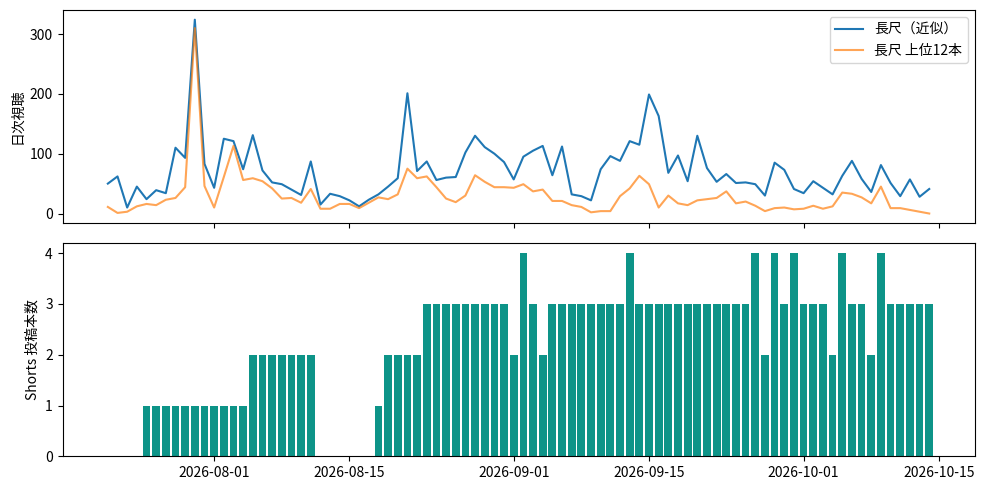

In [2]:
fig, ax = plt.subplots(2, 1, figsize=(10, 5), sharex=True)
ax[0].plot(d.index, d['長尺'], label='長尺（近似）'); ax[0].plot(d.index, d['長尺_上位12本'], label='長尺 上位12本', alpha=.7); ax[0].legend(); ax[0].set_ylabel('日次視聴')
ax[1].bar(d.index, d['Shorts投稿'], color='#0d9488'); ax[1].set_ylabel('Shorts 投稿本数')
plt.tight_layout(); plt.show()

## 2. 回帰（HAC 標準誤差）

In [3]:
lags = ' + '.join(f'S_lag{k}' for k in range(8))
def fit(y, df=d): return smf.ols(f'{y} ~ {lags} + 長尺投稿 + C(曜日) + トレンド', df).fit(cov_type='HAC', cov_kwds={'maxlags': 7})
m = fit('長尺')
tab = pd.DataFrame({'係数': m.params, '95%下限': m.conf_int()[0], '95%上限': m.conf_int()[1], 'p値': m.pvalues}).round(3)
print(f'n={int(m.nobs)}  R²={m.rsquared:.2f}'); tab.loc[[f'S_lag{k}' for k in range(8)] + ['長尺投稿', 'トレンド']]

n=86  R²=0.23


,係数,95%下限,95%上限,p値
S_lag0,15.090,4.801,25.379,0.004
S_lag1,0.424,-13.548,14.395,0.953
S_lag2,5.235,-9.976,20.445,0.500
S_lag3,8.637,-5.435,22.709,0.229
S_lag4,2.843,-13.319,19.006,0.730
S_lag5,0.566,-13.659,14.792,0.938
S_lag6,-9.067,-23.767,5.633,0.227
S_lag7,2.176,-13.353,17.704,0.784
長尺投稿,7.099,-7.552,21.749,0.342
トレンド,-1.014,-1.584,-0.443,0.000


In [4]:
def cum(m):
    t = m.t_test(' + '.join(f'S_lag{k}' for k in range(8)) + ' = 0')
    return float(t.effect[0]), *map(float, t.conf_int()[0]), float(t.pvalue)
res = pd.DataFrame([cum(m), cum(fit('長尺_上位12本')), cum(fit('np.log1p(長尺)'))],
    index=['長尺（近似）', '長尺 上位12本', 'log(1＋長尺)'], columns=['8日合計の効果', '95%下限', '95%上限', 'p値']).round(3)
res

,8日合計の効果,95%下限,95%上限,p値
長尺（近似）,25.903,10.288,41.518,0.001
長尺 上位12本,5.166,-6.616,16.948,0.390
log(1＋長尺),0.466,0.269,0.664,0.000


**注意**：近似の目的変数には、新しい Shorts が「ブラウジング」「検索」「関連動画」経由で得た視聴も混ざる。当日（ラグ0）の大きな係数はこの混入の可能性が高いので、**当日を除いた 1〜7日後の合計**と、純粋な長尺（上位12本）の結果を主に見る

In [5]:
def cum17(m):
    t = m.t_test(' + '.join(f'S_lag{k}' for k in range(1, 8)) + ' = 0')
    return float(t.effect[0]), *map(float, t.conf_int()[0]), float(t.pvalue)
res17 = pd.DataFrame([cum17(m), cum17(fit('長尺_上位12本')), cum17(fit('np.log1p(長尺)'))],
    index=['長尺（近似）', '長尺 上位12本', 'log(1＋長尺)'], columns=['1〜7日後の合計', '95%下限', '95%上限', 'p値']).round(3)
res17

,1〜7日後の合計,95%下限,95%上限,p値
長尺（近似）,10.813,-7.386,29.012,0.244
長尺 上位12本,-2.324,-13.269,8.621,0.677
log(1＋長尺),0.146,-0.101,0.394,0.246


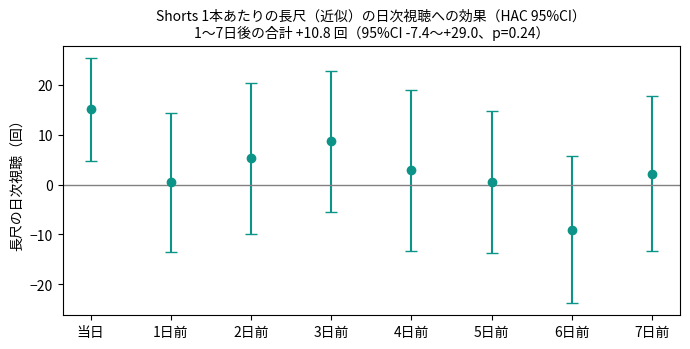

In [6]:
k = [f'S_lag{i}' for i in range(8)]; ci = m.conf_int().loc[k]
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.errorbar(range(8), m.params[k], yerr=[m.params[k] - ci[0], ci[1] - m.params[k]], fmt='o', color='#0d9488', capsize=4)
ax.axhline(0, color='grey', lw=1); ax.set_xticks(range(8), [f'{i}日前' if i else '当日' for i in range(8)])
c = res17.iloc[0]; ax.set_title(f'Shorts 1本あたりの長尺（近似）の日次視聴への効果（HAC 95%CI）\n1〜7日後の合計 {c.iloc[0]:+.1f} 回（95%CI {c.iloc[1]:+.1f}〜{c.iloc[2]:+.1f}、p={c.iloc[3]:.2f}）', fontsize=10)
ax.set_ylabel('長尺の日次視聴（回）'); plt.tight_layout(); plt.savefig('../images/shorts_lag_effect.png', dpi=150); plt.show()

## 3. 残差の確認

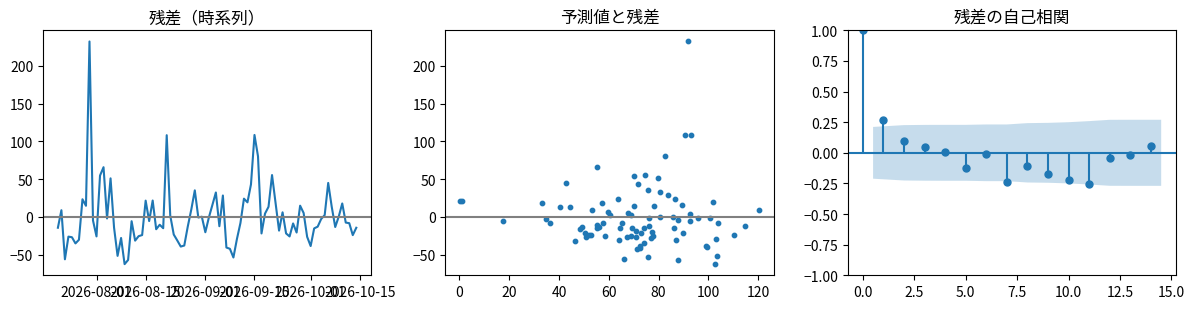

Ljung-Box（ラグ7）p = 0.043
Breusch-Pagan p = 0.84


In [7]:
r = m.resid
fig, ax = plt.subplots(1, 3, figsize=(12, 3.2))
ax[0].plot(r.index, r); ax[0].axhline(0, color='grey'); ax[0].set_title('残差（時系列）')
ax[1].scatter(m.fittedvalues, r, s=10); ax[1].axhline(0, color='grey'); ax[1].set_title('予測値と残差')
plot_acf(r, lags=14, ax=ax[2]); ax[2].set_title('残差の自己相関')
plt.tight_layout(); plt.show()
print('Ljung-Box（ラグ7）p =', round(float(acorr_ljungbox(r, lags=[7])['lb_pvalue'].iloc[0]), 3))
print('Breusch-Pagan p =', round(het_breuschpagan(r, m.model.exog)[1], 3))

## 4. 結論（3行）

In [8]:
print(res.round(1)); print(res17.round(1))

           8日合計の効果  95%下限  95%上限   p値
長尺（近似）        25.9   10.3   41.5  0.0
長尺 上位12本       5.2   -6.6   16.9  0.4
log(1＋長尺)      0.5    0.3    0.7  0.0
           1〜7日後の合計  95%下限  95%上限   p値
長尺（近似）         10.8   -7.4   29.0  0.2
長尺 上位12本       -2.3  -13.3    8.6  0.7
log(1＋長尺)       0.1   -0.1    0.4  0.2


**結論（3行）**
1. **言えること**：Shorts を出した**当日**は長尺（近似）の視聴が1本あたり約 +15 回多いが、これは新しい Shorts 自身がブラウジング・検索経由で得た視聴の混入でほぼ説明できる（純粋な長尺＝上位12本では当日も含めて有意差なし）
2. **言えること**：**翌日〜7日後**の押し上げは、近似 +10.8 回（95%CI −7.4〜+29.0）・上位12本 −2.3 回（−13.3〜+8.6）で、どちらもゼロと区別できない。この86日では「Shorts が長尺を引っぱる」ははっきり見えない
3. **言えないこと**：「効果がない」とは言えない（期間が短く CI が広い）。投稿日は自分で選んでいるので因果も言えない。残差に弱い自己相関（Ljung-Box p=0.04）が残るため HAC で補正したが、検出力は高くない